In [1]:
# Import library utama TensorFlow dan Keras
import tensorflow as tf
from tensorflow.keras.applications import EfficientNetV2B0
from tensorflow.keras.layers import (GlobalAveragePooling2D, Dense, Input, Dropout, 
                                     RandomFlip, RandomRotation, RandomZoom,
                                     RandomTranslation, RandomBrightness, RandomContrast)

from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from tensorflow.keras.models import Model, Sequential
from tensorflow.keras.optimizers import Adam, Adamax, Nadam, SGD, RMSprop # <-- MENAMBAHKAN SEMUA OPTIMIZER

# Import library untuk manipulasi data dan plotting
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Import library untuk evaluasi dari Scikit-learn
from sklearn.metrics import confusion_matrix, classification_report

print("Semua library berhasil diimpor.")
print(f"Versi TensorFlow: {tf.__version__}")

Semua library berhasil diimpor.
Versi TensorFlow: 2.15.0


In [53]:
# --- KONFIGURASI UTAMA ---

# GANTI DENGAN PATH YANG BENAR DI KOMPUTER ANDA
DATA_DIR = r"C:\Users\abima\OneDrive\Documents\SKRIPSI\SEMHAS\data_train" 

# Parameter untuk gambar dan model
IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32

# Parameter untuk proses training
# Kita bagi menjadi 2 tahap: pelatihan awal dan fine-tuning
INITIAL_EPOCHS = 15
FINE_TUNE_EPOCHS = 10
EXPERIMENT_EPOCHS = 15

In [54]:
print("Memuat dataset...")
# Memuat data training (80% dari data)
train_data = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR,
    validation_split=0.2,
    subset="training",
    seed=123,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='int'
)

# Memuat data validasi (20% dari data)
val_data = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR,
    validation_split=0.2,
    subset="validation",
    seed=123,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='int'
)

# Mengambil nama kelas dan jumlah kelas
class_names = train_data.class_names
NUM_CLASSES = len(class_names)
print(f"Ditemukan {NUM_CLASSES} kelas: {class_names}") 

# class_names sudah dari: class_names = train_data.class_names
label_to_index = {name: idx for idx, name in enumerate(class_names)}

import json, os
with open('class_indices.json', 'w') as f:
    json.dump(label_to_index, f)

print("Saved:", os.path.abspath('class_indices.json'))
print(label_to_index)


# Mengoptimalkan pipeline data untuk kecepatan
AUTOTUNE = tf.data.AUTOTUNE
train_data = train_data.cache().shuffle(1000).prefetch(buffer_size=AUTOTUNE)
val_data = val_data.cache().prefetch(buffer_size=AUTOTUNE)
print("Dataset siap digunakan dan telah dioptimalkan.")

Memuat dataset...
Found 10946 files belonging to 6 classes.
Using 8757 files for training.
Found 10946 files belonging to 6 classes.
Using 2189 files for validation.
Ditemukan 6 kelas: ['bercak_daun', 'blast', 'bukan_padi', 'hawar_daun', 'normal', 'tungro']
Saved: c:\Users\abima\OneDrive\Documents\SKRIPSI\SEMHAS\class_indices.json
{'bercak_daun': 0, 'blast': 1, 'bukan_padi': 2, 'hawar_daun': 3, 'normal': 4, 'tungro': 5}
Dataset siap digunakan dan telah dioptimalkan.


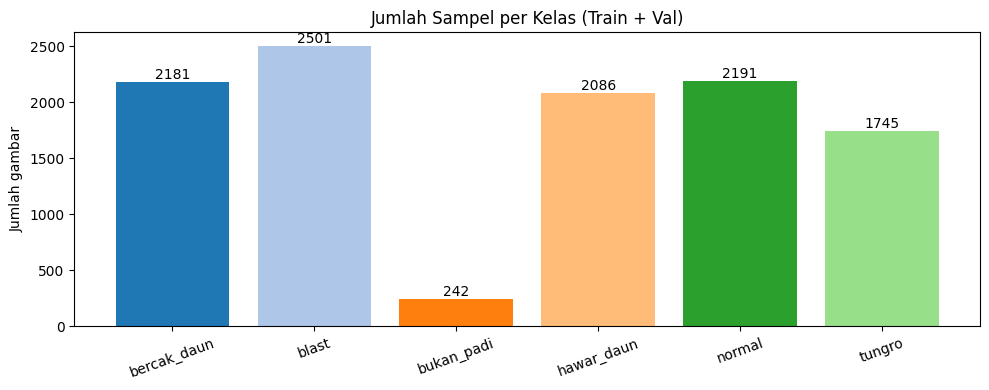

In [4]:
# ── BAR CHART: Jumlah sampel per kelas 
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter

def count_labels(ds):
    cnt = Counter()
    for _, y in ds.unbatch():
        cnt[int(y.numpy())] += 1
    return cnt

train_counts = count_labels(train_data)
val_counts   = count_labels(val_data)
all_counts   = {i: train_counts.get(i, 0) + val_counts.get(i, 0) for i in range(NUM_CLASSES)}

idx     = np.arange(NUM_CLASSES)
values  = [all_counts.get(i, 0) for i in range(NUM_CLASSES)]
colors  = plt.cm.tab20(idx % 20)   # warna-warni seperti contoh

plt.figure(figsize=(10, 4))
bars = plt.bar(idx, values, color=colors, edgecolor='none')

# Tampilkan label nilai di atas tiap batang
for b, v in zip(bars, values):
    plt.text(b.get_x() + b.get_width()/2, v, f"{v}", ha='center', va='bottom', fontsize=10)

plt.xticks(idx, class_names, rotation=20)
plt.ylabel("Jumlah gambar")
plt.title("Jumlah Sampel per Kelas (Train + Val)")
plt.tight_layout()
plt.show()


In [56]:
# ─────────────────────────────────────────────────────────────────
# TRAIN DENGAN GABUNGAN: DATA AUGMENTASI  +  DATA CLAHE (TERPISAH)
# ─────────────────────────────────────────────────────────────────
import tensorflow as tf
import numpy as np

AUTOTUNE = tf.data.AUTOTUNE

# 1) Pastikan punya layer augmentasi (atau buat yang sederhana)
try:
    data_augmentation  # jika sudah ada di notebook
except NameError:
    from tensorflow.keras import Sequential
    from tensorflow.keras.layers import RandomFlip, RandomRotation, RandomTranslation, RandomZoom, RandomBrightness, RandomContrast
    data_augmentation = Sequential([
        RandomFlip("horizontal"),
        RandomRotation(0.1),
        RandomTranslation(0.08, 0.08),
        RandomZoom(0.1),
        RandomBrightness(0.12),
        RandomContrast(0.12),
    ], name="rich_data_augmentation")

# 2) Utility: terapkan CLAHE pada RGB via tf.py_function (CLAHE hanya di kanal Y)
@tf.function
def _clahe_numpy(rgb):
    # fungsi ini dipanggil di py_function; isi tetap NumPy/OpenCV
    import cv2
    rgb = rgb.numpy()  # uint8 [H,W,3]
    ycrcb = cv2.cvtColor(rgb, cv2.COLOR_RGB2YCrCb)
    Y, Cr, Cb = cv2.split(ycrcb)
    clahe = cv2.createCLAHE(clipLimit=2.5, tileGridSize=(8,8))  # PARAMETER BISA DISUAIKAN
    Y_eq = clahe.apply(Y)
    out = cv2.cvtColor(cv2.merge([Y_eq, Cr, Cb]), cv2.COLOR_YCrCb2RGB)
    return out

def apply_clahe_tf(image, label):
    # image: uint8 [H,W,3] (single example)
    out = tf.py_function(func=_clahe_numpy, inp=[image], Tout=tf.uint8)
    out.set_shape(image.shape)  # jaga bentuk
    return out, label

def apply_augment_tf(image, label):
    # data_augmentation menerima float; normalisasi ke [0,1] dulu lalu kembalikan ke [0,255] uint8
    x = tf.image.convert_image_dtype(image, tf.float32)
    x = data_augmentation(x, training=True)
    x = tf.clip_by_value(x, 0.0, 1.0)
    x = tf.image.convert_image_dtype(x, tf.uint8)
    return x, label

# 3) Ambil dataset training dasar dari yang sudah kamu punya
#    Misal variabelnya: train_data (subset="training") dan val_data (subset="validation")
#    train_data & val_data biasanya sudah batched oleh image_dataset_from_directory.
#    Agar mudah dipetakan per gambar, kita unbatch → map → batch lagi.
def make_augmented(train_ds, batch_size):
    ds = (train_ds
          .unbatch()
          .map(apply_augment_tf, num_parallel_calls=AUTOTUNE)
          .batch(batch_size)
          .prefetch(AUTOTUNE))
    return ds

def make_clahe(train_ds, batch_size):
    ds = (train_ds
          .unbatch()
          .map(apply_clahe_tf, num_parallel_calls=AUTOTUNE)
          .batch(batch_size)
          .prefetch(AUTOTUNE))
    return ds

aug_train_ds   = make_augmented(train_data, BATCH_SIZE)
clahe_train_ds = make_clahe(train_data, BATCH_SIZE)

# 4) GABUNGKAN KEDUA ALIRAN (augmentasi + CLAHE) sebagai satu dataset training
#    Opsi A (sederhana): concatenate → ukuran dataset ≈ 2x
combined_train_ds = (aug_train_ds.concatenate(clahe_train_ds)
                     .shuffle(8 * BATCH_SIZE, reshuffle_each_iteration=True)
                     .prefetch(AUTOTUNE))

#    Opsi B (opsional): sampling campuran 50:50 tanpa menggandakan ukuran epoch
# combined_train_ds = tf.data.Dataset.sample_from_datasets(
#     [aug_train_ds, clahe_train_ds],
#     weights=[0.5, 0.5],
#     stop_on_empty_dataset=False
# ).prefetch(AUTOTUNE)

# 5) Normalisasi untuk model (jika model kamu TIDAK punya layer Rescaling di dalamnya)
#    Jika di build_model sudah ada tf.keras.layers.Rescaling(1./255), LEWATI langkah ini.
def to_float(image, label):
    return tf.image.convert_image_dtype(image, tf.float32), label

needs_rescaling_in_model = False  # ubah ke True jika build_model sudah mengurus rescaling
if not needs_rescaling_in_model:
    combined_train_ds = combined_train_ds.map(to_float, num_parallel_calls=AUTOTUNE)
    val_data = val_data.map(to_float, num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)
else:
    # kalau model sudah melakukan Rescaling sendiri, cukup prefetch saja
    val_data = val_data.prefetch(AUTOTUNE)

# 6) TRAIN dengan dataset gabungan
#    Ganti train_data → combined_train_ds pada fit(); val_data tetap sama.
#    Contoh:
# history = model.fit(combined_train_ds, validation_data=val_data, epochs=EPOCHS)

print("✅ Dataset gabungan siap dipakai: augmentasi + CLAHE (tanpa chaining).")


✅ Dataset gabungan siap dipakai: augmentasi + CLAHE (tanpa chaining).


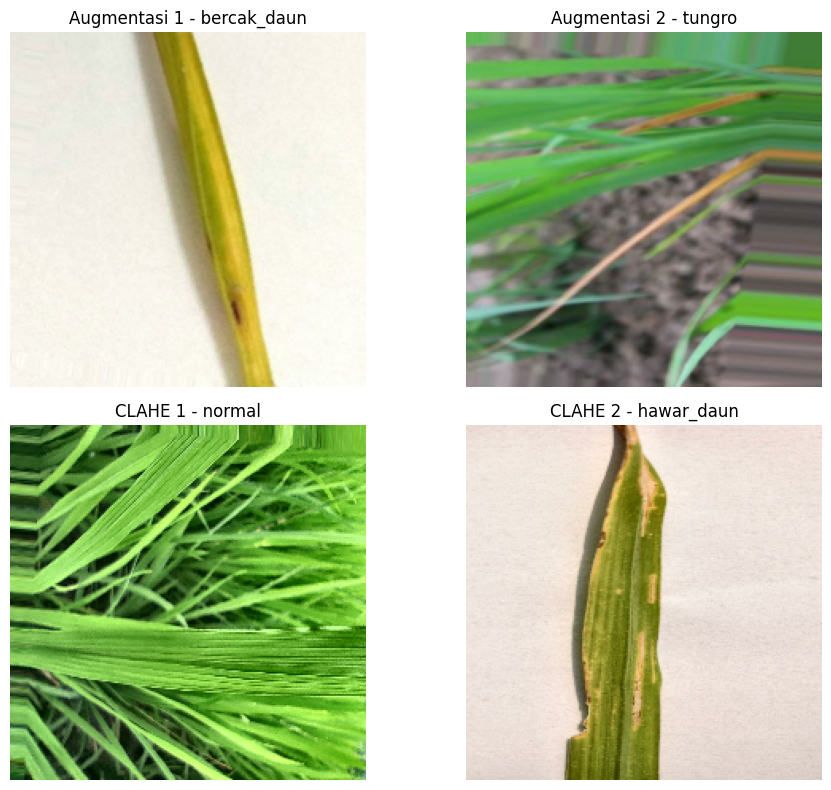

In [57]:
# ─────────────────────────────────────────────────────────────
# PREVIEW STABIL & PASTI MUNCUL:
# 2 AUGMENTASI (aman) + 2 CLAHE (tanpa chaining)
# ─────────────────────────────────────────────────────────────
import tensorflow as tf, numpy as np, matplotlib.pyplot as plt, cv2
tf.random.set_seed(123); np.random.seed(123)

# 1) Augmentasi AMAN (flip + rotasi kecil)
from tensorflow.keras import Sequential
from tensorflow.keras.layers import RandomFlip, RandomRotation

safe_aug = Sequential([
    RandomFlip("horizontal"),
    RandomRotation(0.03, fill_mode='reflect', interpolation='bilinear'),  # ~±3°
], name="safe_aug")

def to_uint8_rgb(arr):
    arr = np.asarray(arr)
    if arr.dtype != np.uint8:
        if arr.max() <= 1.0: arr = (arr*255.0).round().astype(np.uint8)
        else: arr = np.clip(arr, 0, 255).astype(np.uint8)
    # pastikan 3 channel RGB
    if arr.ndim == 2:
        arr = cv2.cvtColor(arr, cv2.COLOR_GRAY2RGB)
    elif arr.shape[-1] == 4:
        arr = cv2.cvtColor(arr, cv2.COLOR_RGBA2RGB)
    return np.ascontiguousarray(arr)

def center_variance(img, m=0.35):
    """variansi patch tengah (indikator 'bukan blank'); m=proporsi sisi patch tengah."""
    H, W = img.shape[:2]
    y0, y1 = int(H*(0.5-m/2)), int(H*(0.5+m/2))
    x0, x1 = int(W*(0.5-m/2)), int(W*(0.5+m/2))
    patch = img[y0:y1, x0:x1]
    return float(patch.std())

def augment_once_safe(img_u8, tries=8, min_mean=12, min_std=6, min_center_std=5):
    """Coba beberapa kali sampai hasil tidak blank/gelap."""
    base = tf.image.convert_image_dtype(tf.convert_to_tensor(img_u8), tf.float32)  # [0,1]
    for _ in range(tries):
        x = tf.expand_dims(base, 0)
        x = safe_aug(x, training=True)
        x = tf.squeeze(x, 0)
        x = tf.clip_by_value(x, 0.0, 1.0)
        x = tf.image.convert_image_dtype(x, tf.uint8).numpy()
        if x.mean() >= min_mean and x.std() >= min_std and center_variance(x) >= min_center_std:
            return x
    return x  # fallback terakhir

def clahe_rgb_uint8(img, clip=2.5, tile=(8,8)):
    rgb = to_uint8_rgb(img)
    ycrcb = cv2.cvtColor(rgb, cv2.COLOR_RGB2YCrCb)
    Y, Cr, Cb = cv2.split(ycrcb)
    Yeq = cv2.createCLAHE(clipLimit=clip, tileGridSize=tile).apply(Y.astype(np.uint8))
    return cv2.cvtColor(cv2.merge([Yeq, Cr, Cb]), cv2.COLOR_YCrCb2RGB)

# 2) Kumpulkan 4 sampel mentah aman dari train_data
raw_imgs, raw_lbl = [], []
for img, y in train_data.unbatch().take(40).as_numpy_iterator():
    try:
        raw_imgs.append(to_uint8_rgb(img)); raw_lbl.append(int(y))
        if len(raw_imgs) == 4: break
    except:
        continue
if len(raw_imgs) < 4:
    raise RuntimeError("Kurang sampel untuk preview. Pastikan train_data berisi gambar.")

# 3) Bangun 2 AUG + 2 CLAHE
aug1 = augment_once_safe(raw_imgs[0])
aug2 = augment_once_safe(raw_imgs[1])
cl1  = clahe_rgb_uint8(raw_imgs[2])
cl2  = clahe_rgb_uint8(raw_imgs[3])

# 4) Nama kelas (jika tersedia)
try: class_labels = list(class_names)
except NameError: class_labels = getattr(train_data, "class_names", None)
def label_to_name(i): return class_labels[i] if (class_labels and 0 <= i < len(class_labels)) else str(i)

# 5) Plot 2×2
plt.figure(figsize=(10,8))
ax=plt.subplot(2,2,1); ax.imshow(aug1); ax.set_title(f"Augmentasi 1 - {label_to_name(raw_lbl[0])}"); ax.axis("off")
ax=plt.subplot(2,2,2); ax.imshow(aug2); ax.set_title(f"Augmentasi 2 - {label_to_name(raw_lbl[1])}"); ax.axis("off")
ax=plt.subplot(2,2,3); ax.imshow(cl1);  ax.set_title(f"CLAHE 1 - {label_to_name(raw_lbl[2])}");   ax.axis("off")
ax=plt.subplot(2,2,4); ax.imshow(cl2);  ax.set_title(f"CLAHE 2 - {label_to_name(raw_lbl[3])}");   ax.axis("off")
plt.tight_layout(); plt.show()


In [65]:
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import RandomFlip, RandomRotation, RandomZoom, RandomContrast

# RandomBrightness mungkin tidak ada di versi Keras tertentu; pakai kalau tersedia
try:
    from tensorflow.keras.layers import RandomBrightness
    HAS_RAND_BRIGHTNESS = True
except Exception:
    HAS_RAND_BRIGHTNESS = False

# Bersihkan graph & hapus augmentation lama (yang salah shape)
tf.keras.backend.clear_session()
try:
    del data_augmentation
except NameError:
    pass

# Definisikan ulang TANPA input_shape/InputLayer 3D
layers_list = [
    RandomFlip("horizontal"),
    RandomRotation(0.10, fill_mode="reflect"),
    RandomZoom(0.10, fill_mode="reflect"),
    RandomContrast(0.10),
]
if HAS_RAND_BRIGHTNESS:
    layers_list.append(RandomBrightness(0.10))

data_augmentation = Sequential(layers_list, name="data_augmentation")

# Cek cepat (harus (1,H,W,3))
H, W = IMAGE_SIZE
_dummy = tf.ones((1, H, W, 3), dtype=tf.float32)
print("OK →", data_augmentation(_dummy, training=True).shape)



OK → (1, 224, 224, 3)


In [72]:
# =============================================================
# FIX SHAPE ERROR: buang augmentasi di model (augment sudah di tf.data)
# =============================================================
import tensorflow as tf
from tensorflow.keras import Input, Model
from tensorflow.keras.layers import GlobalAveragePooling2D, Dropout, Dense
from tensorflow.keras.applications import EfficientNetV2B0

# 1) Reset graph agar objek augmentation lama tidak nyangkut
tf.keras.backend.clear_session()

# 2) Definisikan ulang build_model TANPA data_augmentation di dalam model
def build_model(optimizer_object):
    H, W = IMAGE_SIZE  # pastikan IMAGE_SIZE=(224,224) atau sesuai dataset

    # INPUT 4D
    inputs = Input(shape=(H, W, 3), name="input_layer")

    # Penting: DATASET kamu SUDAH float32 [0..1] (dari pipeline augment+CLAHE),
    # maka JANGAN Rescaling lagi di model. Kalau datasetmu masih uint8 0..255,
    # baru pakai Rescaling(1./255) di sini.
    x = inputs  # <-- TIDAK ADA Rescaling di model

    # TIDAK ADA data_augmentation(x) DI SINI (augment sudah di pipeline tf.data)

    # BACKBONE
    base_model = EfficientNetV2B0(
        input_shape=(H, W, 3),
        include_top=False,
        weights='imagenet'
    )
    base_model.trainable = False
    x = base_model(x, training=False)

    # HEAD
    x = GlobalAveragePooling2D()(x)
    x = Dropout(0.2)(x)
    outputs = Dense(NUM_CLASSES, activation='softmax', name="output_layer")(x)

    model = Model(inputs, outputs)
    model.compile(
        optimizer=optimizer_object,
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

# 3) Sanity check: pastikan batch dari train_data sudah float32 [0..1]
for xb, yb in train_data.take(1):
    print("train_data batch dtype/range:", xb.dtype, float(tf.reduce_min(xb)), float(tf.reduce_max(xb)))
    break
# Harus: float32 ~ 0.0..1.0 (karena apply_augment_tf/apply_clahe_tf sudah convert)


: 

In [70]:
# ==== 0) Import & setup ====
import tensorflow as tf, numpy as np, cv2
AUTOTUNE = tf.data.AUTOTUNE

# ==== 1) Augmentasi stream (pakai punyamu jika sudah ada) ====
from tensorflow.keras import Sequential
from tensorflow.keras.layers import (RandomFlip, RandomRotation, RandomTranslation,
                                     RandomZoom, RandomBrightness, RandomContrast)

data_augmentation = Sequential([
    RandomFlip("horizontal"),
    RandomRotation(0.10),
    RandomTranslation(0.08, 0.08),
    RandomZoom(0.10),
    RandomBrightness(0.12),
    RandomContrast(0.12),
], name="rich_data_augmentation")

def apply_augment_tf(image, label):
    # Jika model TIDAK punya layer Rescaling, kita jadikan float32 [0,1]
    x = tf.image.convert_image_dtype(image, tf.float32)
    x = data_augmentation(x, training=True)
    x = tf.clip_by_value(x, 0.0, 1.0)
    return x, label

# ==== 2) CLAHE stream (hanya CLAHE; tidak di-augment) ====
def _clahe_numpy(rgb_u8):
    # rgb_u8: uint8 [H,W,3] in RGB
    ycrcb = cv2.cvtColor(rgb_u8, cv2.COLOR_RGB2YCrCb)
    Y, Cr, Cb = cv2.split(ycrcb)
    Yeq = cv2.createCLAHE(clipLimit=2.5, tileGridSize=(8,8)).apply(Y.astype(np.uint8))
    return cv2.cvtColor(cv2.merge([Yeq, Cr, Cb]), cv2.COLOR_YCrCb2RGB)

def apply_clahe_tf(image, label):
    img_u8 = tf.image.convert_image_dtype(image, tf.uint8, saturate=True)         # pastikan uint8
    out_u8 = tf.py_function(_clahe_numpy, [img_u8], Tout=tf.uint8)
    out_u8.set_shape(image.shape)                                                 # jaga shape
    out = tf.image.convert_image_dtype(out_u8, tf.float32)                        # ke [0,1] agar konsisten
    return out, label

# ==== 3) Buat dua stream dari train_data asli ====
aug_ds = (train_data
          .unbatch()
          .map(apply_augment_tf, num_parallel_calls=AUTOTUNE)
          .batch(BATCH_SIZE)
          .prefetch(AUTOTUNE))

clahe_ds = (train_data
            .unbatch()
            .map(apply_clahe_tf, num_parallel_calls=AUTOTUNE)
            .batch(BATCH_SIZE)
            .prefetch(AUTOTUNE))

# ==== 4) Gabungkan stream (pilih salah satu) ====
# Opsi A: concatenate → ukuran epoch ~ 2x (semua data augment + semua data CLAHE)
combined_train_ds = (aug_ds.concatenate(clahe_ds)
                     .shuffle(8 * BATCH_SIZE, reshuffle_each_iteration=True)
                     .prefetch(AUTOTUNE))

# (Alternatif Opsi B): campur 50:50 tanpa memperbesar ukuran epoch
# combined_train_ds = tf.data.Dataset.sample_from_datasets(
#     [aug_ds, clahe_ds], weights=[0.5, 0.5], stop_on_empty_dataset=False
# ).prefetch(AUTOTUNE)

# ==== 5) Pakai gabungan ini untuk training ====
train_data = combined_train_ds

# (opsional) jika val_data masih uint8 dan model TIDAK punya Rescaling:
# val_data = val_data.map(lambda x,y: (tf.image.convert_image_dtype(x, tf.float32), y),
#                         num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)


In [71]:
# ─────────────────────────────────────────────────────────────────────────────
# PERBANDINGAN OPTIMIZER + METRIK AKHIR (ACC, PREC, REC, F1) & CONFUSION MATRIX
# (Satu blok lengkap: tinggal tempel. Kode aslimu dipertahankan, hanya ada penambahan.)
# ─────────────────────────────────────────────────────────────────────────────
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score
import numpy as np
import matplotlib.pyplot as plt

# (opsional) jika val_data adalah tf.data.Dataset, agar bisa di-iterate berkali-kali:
# val_data = val_data.cache().prefetch(tf.data.AUTOTUNE)

# ── SIMPAN MODEL TERLATIH PER OPTIMIZER UNTUK DIEVALUASI SETELAH LOOP ──
trained_models = {}

# 1. Definisikan dictionary optimizer
optimizers_to_compare = {
    "Adam": Adam,
    "Adamax": Adamax,
    "Nadam": Nadam,
    "SGD": SGD,
    "RMSprop": RMSprop
}

# 2. Siapkan dictionary kosong untuk menyimpan hasil
results = {}

# 3. Loop utama untuk training dan evaluasi
for optimizer_name, optimizer_class in optimizers_to_compare.items():
    print(f"\n{'='*25}\n   UJI COBA OPTIMIZER: {optimizer_name}\n{'='*25}")
    
    # Buat instance dari optimizer dengan learning rate awal yang sama
    optimizer_instance = optimizer_class(learning_rate=0.001)
    
    # Bangun ulang model agar bobot reset
    model_experiment = build_model(optimizer_instance)
    
    print(f"Memulai training dengan {optimizer_name} untuk {EXPERIMENT_EPOCHS} epochs...\n")
    
    # Latih model dan tampilkan progress setiap epoch
    history = model_experiment.fit(
        train_data,
        validation_data=val_data,
        epochs=EXPERIMENT_EPOCHS,
        verbose=1  # <-- menampilkan progress setiap epoch
    )
    print("\nTraining selesai.")
    
    # Evaluasi model
    print(f"Evaluasi model dengan {optimizer_name}...")
    loss, accuracy = model_experiment.evaluate(val_data, verbose=0)
    print(f">>> Hasil {optimizer_name}: Akurasi Validasi = {accuracy:.4f}, Loss = {loss:.4f}")
    
    # (PENAMBAHAN) simpan model untuk evaluasi akhir setelah loop
    trained_models[optimizer_name] = model_experiment
    
    # Simpan hasil
    results[optimizer_name] = accuracy

# 4. Menampilkan hasil perbandingan
print(f"\n\n{'='*25}\n   HASIL AKHIR PERBANDINGAN OPTIMIZER\n{'='*25}")
sorted_results = sorted(results.items(), key=lambda item: item[1], reverse=True)

print("Peringkat Optimizer Berdasarkan Akurasi Validasi Tertinggi:")
for i, (optimizer_name, accuracy) in enumerate(sorted_results):
    print(f"{i+1}. {optimizer_name}: Akurasi = {accuracy:.4f}")
    
# Visualisasi hasil
plt.figure(figsize=(12, 7))
bars = plt.bar(list(results.keys()), list(results.values()), color=plt.cm.plasma(np.linspace(0.3, 0.9, len(results))))
plt.xlabel('Optimizer', fontsize=12)
plt.ylabel('Akurasi Validasi Final', fontsize=12)
plt.title('Perbandingan Akurasi Validasi Antar Optimizer', fontsize=16)
plt.ylim([min(results.values()) * 0.95, max(results.values()) * 1.02])

for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval, f'{yval:.4f}', va='bottom', ha='center', fontsize=11)

plt.show()

# Simpan nama optimizer terbaik
WINNING_OPTIMIZER_NAME = sorted_results[0][0]
print(f"\nOptimizer terbaik adalah: {WINNING_OPTIMIZER_NAME}")

# ─────────────────────────────────────────────────────────────────────────────
# EVALUASI AKHIR: CETAK AKURASI, PRESISI, RECALL, F1 (macro) + CONFUSION MATRIX
# untuk SETIAP OPTIMIZER, DIJALANKAN SETELAH LOOP (tanpa mengubah loop asli)
# ─────────────────────────────────────────────────────────────────────────────
print("\n" + "="*25)
print("   EVALUASI AKHIR PER OPTIMIZER (ACC, PREC, REC, F1, CM)")
print("="*25)

# Ambil y_true sekali dari val_data (hemat waktu)
y_true = np.concatenate([y.numpy() for _, y in val_data], axis=0)
class_labels = list(class_names) if 'class_names' in globals() else [str(i) for i in sorted(np.unique(y_true))]
labels = list(range(len(class_labels)))

final_metrics = {}

for opt_name, model in trained_models.items():
    # Prediksi pada validation set
    y_proba = model.predict(val_data, verbose=0)
    y_pred  = np.argmax(y_proba, axis=1)

    # Skor akhir (macro)
    acc_final  = float((y_pred == y_true).mean())
    prec_final = float(precision_score(y_true, y_pred, average='macro',  zero_division=0))
    rec_final  = float(recall_score(  y_true, y_pred, average='macro',  zero_division=0))
    f1_final   = float(f1_score(      y_true, y_pred, average='macro',  zero_division=0))

    print(f"- {opt_name}: Akurasi={acc_final:.4f} | Presisi={prec_final:.4f} | "
          f"Recall={rec_final:.4f} | F1={f1_final:.4f}")

    # Confusion Matrix akhir
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    plt.figure(figsize=(7.5, 6.0))
    plt.imshow(cm, interpolation='nearest')  # tanpa seaborn
    plt.title(f'Confusion Matrix (Akhir) - {opt_name}')
    plt.colorbar()
    tick_marks = np.arange(len(class_labels))
    plt.xticks(tick_marks, class_labels, rotation=45, ha='right')
    plt.yticks(tick_marks, class_labels)
    plt.xlabel('Predicted label')
    plt.ylabel('True label')

    # Tulis angka di tiap sel
    thresh = cm.max() / 2.0 if cm.size > 0 else 0
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            plt.text(j, i, format(cm[i, j], 'd'),
                     ha="center", va="center",
                     color="white" if cm[i, j] > thresh else "black", fontsize=10)
    plt.tight_layout()
    plt.show()

    # Simpan ringkasan jika diperlukan
    final_metrics[opt_name] = {
        "accuracy": acc_final,
        "precision": prec_final,
        "recall": rec_final,
        "f1": f1_final,
        "cm": cm,
    }



   UJI COBA OPTIMIZER: Adam


ValueError: Exception encountered when calling Sequential.call().

[1mInput 0 of layer "functional_2" is incompatible with the layer: expected shape=(None, 224, 3), found shape=(None, 224, 224, 3)[0m

Arguments received by Sequential.call():
  • args=('<KerasTensor shape=(None, 224, 224, 3), dtype=float32, sparse=False, ragged=False, name=keras_tensor_561>',)
  • kwargs={'mask': 'None'}

In [18]:
print(f"\n--- Membangun model final dengan optimizer terbaik: {WINNING_OPTIMIZER_NAME} ---")

# Ambil kelas optimizer pemenang dari dictionary
winning_optimizer_class = optimizers_to_compare[WINNING_OPTIMIZER_NAME]
model = build_model(winning_optimizer_class(learning_rate=0.001))

model.summary()

# 6.1. Pelatihan Awal
print(f"\nMemulai pelatihan awal untuk {INITIAL_EPOCHS} epochs...")
history = model.fit(
    train_data,
    validation_data=val_data,
    epochs=INITIAL_EPOCHS
)
print("\nPelatihan awal selesai.")

# 6.2. Fine-Tuning
print("\n--- Memulai Proses Fine-Tuning ---")
base_model = model.get_layer('efficientnetv2-b0')
base_model.trainable = True
for layer in base_model.layers[:-20]:
    layer.trainable = False

model.compile(
    optimizer=winning_optimizer_class(learning_rate=1e-5), 
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)
print("Model telah di-compile ulang untuk fine-tuning.")

total_epochs = INITIAL_EPOCHS + FINE_TUNE_EPOCHS
history_fine = model.fit(
    train_data,
    epochs=total_epochs,
    initial_epoch=history.epoch[-1],
    validation_data=val_data
)
print("\nProses Fine-tuning selesai.")


--- Membangun model final dengan optimizer terbaik: Nadam ---


Model: "functional_11"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rich_data_augmentation          │ (None, 224, 224, 3)    │             0 │
│ (Sequential)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetv2-b0 (Functional)  │ (None, 7, 7, 1280)     │     5,919,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_10     │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_10 (Dropout)            │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_layer (Dense)            │ (None, 6)              │         7,686 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,926,998 (22.61 MB)

 Trainable params: 7,686 (30.02 KB)

 Non-trainable params: 5,919,312 (22.58 MB)


Memulai pelatihan awal untuk 15 epochs...
Epoch 1/15
274/274 ━━━━━━━━━━━━━━━━━━━━ 186s 646ms/step - accuracy: 0.6219 - loss: 1.0050 - val_accuracy: 0.8515 - val_loss: 0.4520
Epoch 2/15
274/274 ━━━━━━━━━━━━━━━━━━━━ 172s 626ms/step - accuracy: 0.8614 - loss: 0.4255 - val_accuracy: 0.8799 - val_loss: 0.3527
Epoch 3/15
274/274 ━━━━━━━━━━━━━━━━━━━━ 173s 630ms/step - accuracy: 0.8834 - loss: 0.3370 - val_accuracy: 0.8835 - val_loss: 0.3153
Epoch 4/15
274/274 ━━━━━━━━━━━━━━━━━━━━ 168s 614ms/step - accuracy: 0.8933 - loss: 0.3037 - val_accuracy: 0.8968 - val_loss: 0.2881
Epoch 5/15
274/274 ━━━━━━━━━━━━━━━━━━━━ 180s 657ms/step - accuracy: 0.9104 - loss: 0.2715 - val_accuracy: 0.9146 - val_loss: 0.2490
Epoch 6/15
274/274 ━━━━━━━━━━━━━━━━━━━━ 171s 623ms/step - accuracy: 0.9041 - loss: 0.2608 - val_accuracy: 0.9228 - val_loss: 0.2326
Epoch 7/15
274/274 ━━━━━━━━━━━━━━━━━━━━ 168s 612ms/step - accuracy: 0.9162 - loss: 0.2427 - val_accuracy: 0.9205 - val_loss: 0.2278
Epoch 8/15
274/274 ━━━━━━━━━━━━━━


--- Memulai Evaluasi Model Final ---


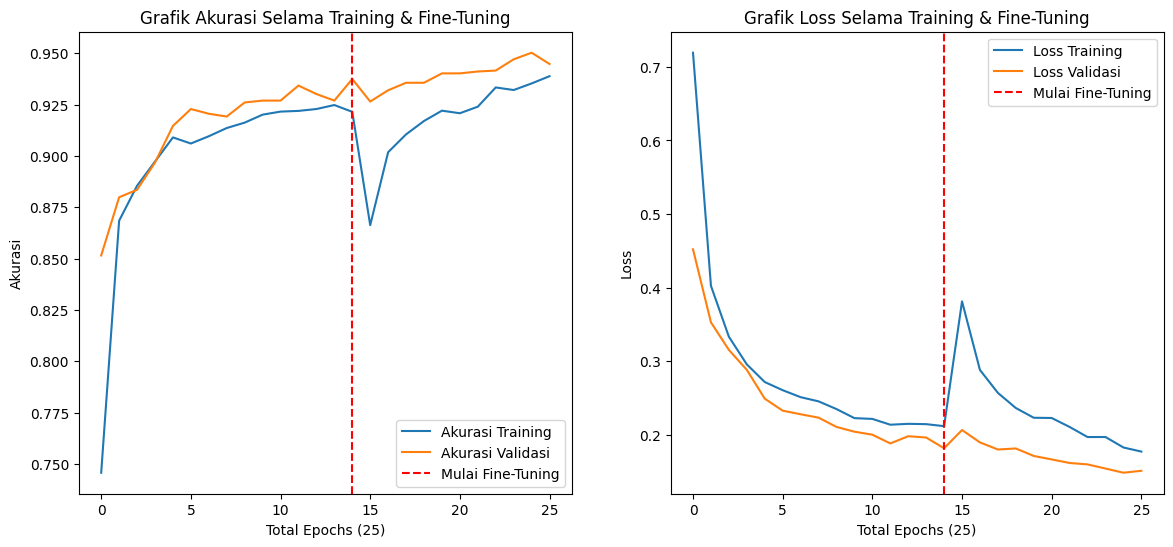


--- Mempersiapkan Matriks Evaluasi pada Data Validasi ---
69/69 ━━━━━━━━━━━━━━━━━━━━ 35s 412ms/step

--- Confusion Matrix ---


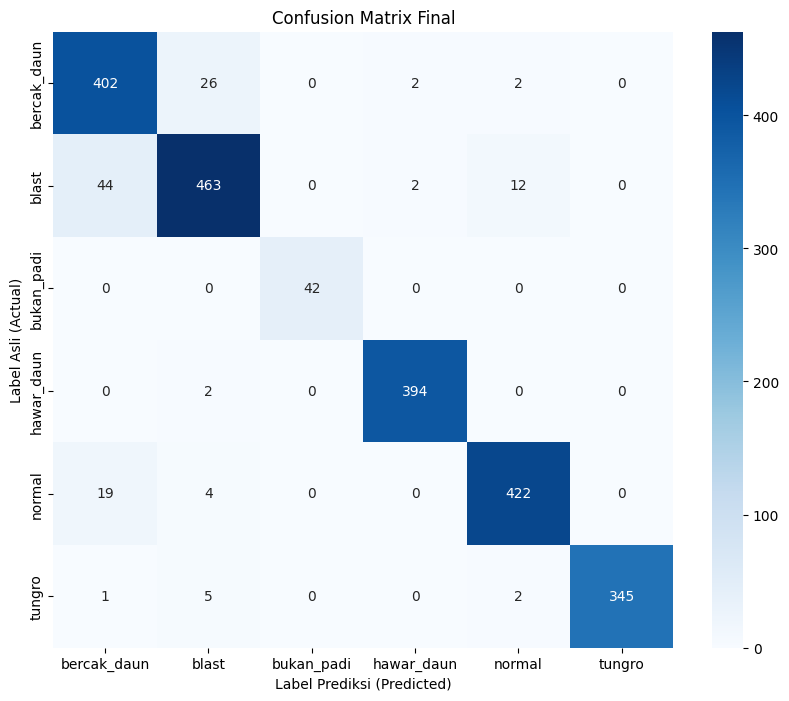


--- Laporan Klasifikasi Final ---
              precision    recall  f1-score   support

 bercak_daun       0.86      0.93      0.90       432
       blast       0.93      0.89      0.91       521
  bukan_padi       1.00      1.00      1.00        42
  hawar_daun       0.99      0.99      0.99       396
      normal       0.96      0.95      0.96       445
      tungro       1.00      0.98      0.99       353

    accuracy                           0.94      2189
   macro avg       0.96      0.96      0.96      2189
weighted avg       0.95      0.94      0.95      2189


--- Contoh Hasil Prediksi pada Data Validasi ---


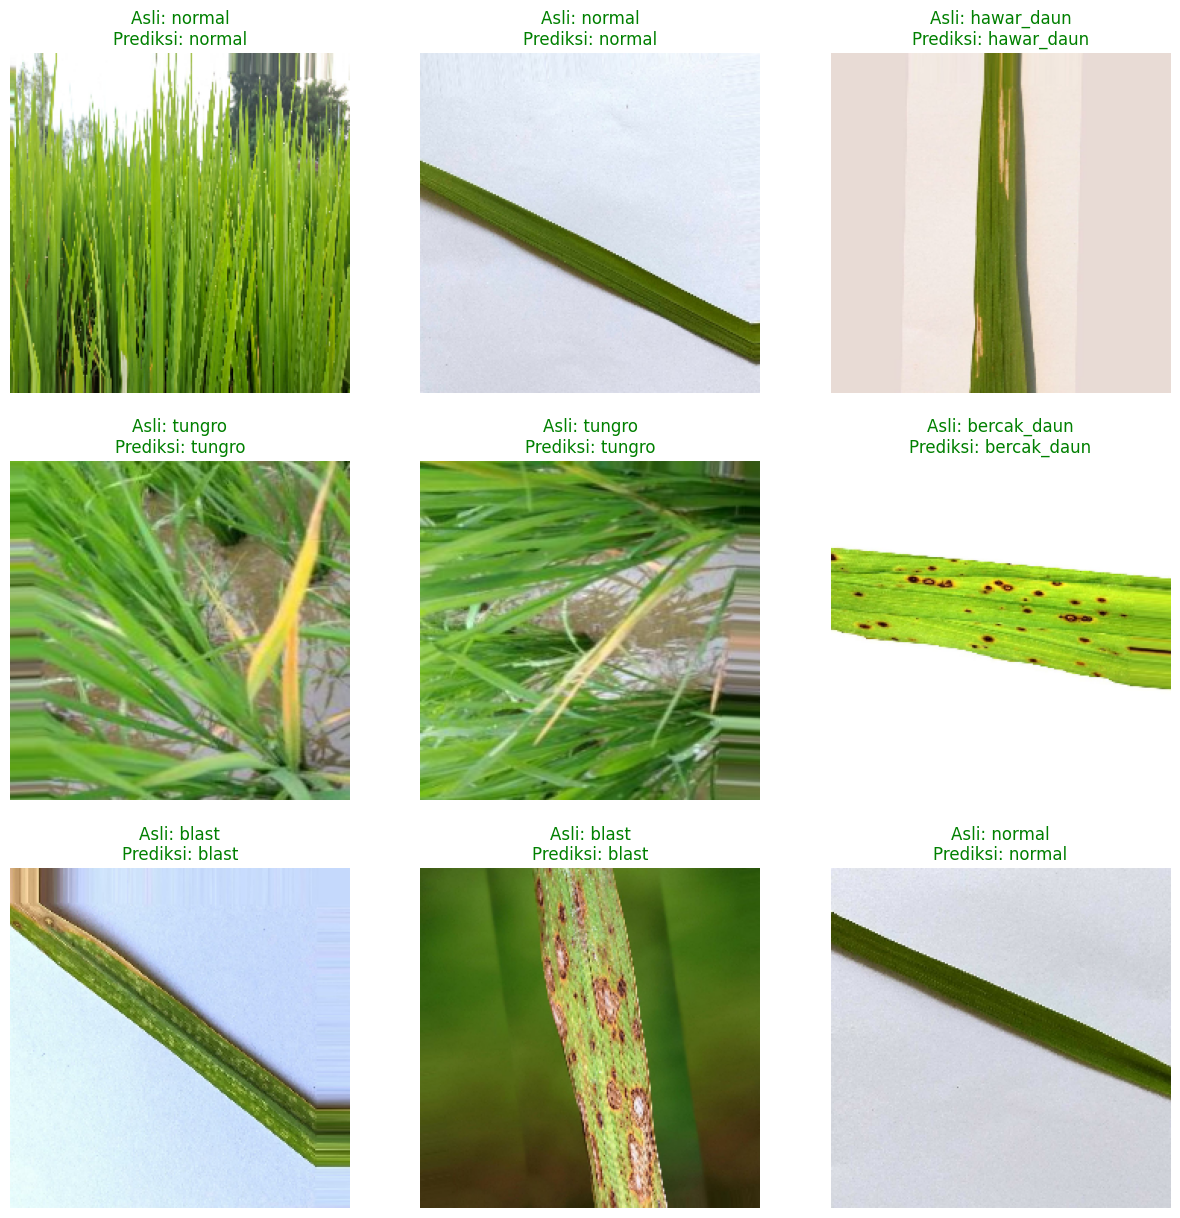

In [19]:
print("\n--- Memulai Evaluasi Model Final ---")


acc = history.history['accuracy'] + history_fine.history['accuracy']
val_acc = history.history['val_accuracy'] + history_fine.history['val_accuracy']
loss = history.history['loss'] + history_fine.history['loss']
val_loss = history.history['val_loss'] + history_fine.history['val_loss']

plt.figure(figsize=(14, 6))
plt.subplot(1, 2, 1)
plt.plot(acc, label='Akurasi Training')
plt.plot(val_acc, label='Akurasi Validasi')
plt.axvline(INITIAL_EPOCHS -1, color='r', linestyle='--', label='Mulai Fine-Tuning')
plt.legend(loc='lower right')
plt.title('Grafik Akurasi Selama Training & Fine-Tuning')
plt.xlabel(f'Total Epochs ({total_epochs})')
plt.ylabel('Akurasi')

plt.subplot(1, 2, 2)
plt.plot(loss, label='Loss Training')
plt.plot(val_loss, label='Loss Validasi')
plt.axvline(INITIAL_EPOCHS - 1, color='r', linestyle='--', label='Mulai Fine-Tuning')
plt.legend(loc='upper right')
plt.title('Grafik Loss Selama Training & Fine-Tuning')
plt.xlabel(f'Total Epochs ({total_epochs})')
plt.ylabel('Loss')
plt.show()

# 7.2. Matriks Evaluasi Detail
print("\n--- Mempersiapkan Matriks Evaluasi pada Data Validasi ---")
predictions = model.predict(val_data)
y_pred = np.argmax(predictions, axis=1)
y_true = np.concatenate([y for x, y in val_data], axis=0)

# Confusion Matrix
print("\n--- Confusion Matrix ---")
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=class_names, yticklabels=class_names)
plt.title('Confusion Matrix Final')
plt.ylabel('Label Asli (Actual)')
plt.xlabel('Label Prediksi (Predicted)')
plt.show()

# Laporan Klasifikasi
print("\n--- Laporan Klasifikasi Final ---")
print(classification_report(y_true, y_pred, target_names=class_names))

# 7.3 Visualisasi Prediksi
print("\n--- Contoh Hasil Prediksi pada Data Validasi ---")
plt.figure(figsize=(15, 15))
for images, labels in val_data.take(1):
    for i in range(9):
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        
        actual_label = class_names[labels[i]]
        predicted_label = class_names[y_pred[i]] # Ambil dari y_pred yang sudah dihitung
        
        title_color = 'green' if actual_label == predicted_label else 'red'
        plt.title(f"Asli: {actual_label}\nPrediksi: {predicted_label}", color=title_color)
        plt.axis("off")
plt.show()

In [20]:
# ==============================================================================
# BAGIAN 8: MENYIMPAN DAN MENGGUNAKAN MODEL FINAL (VERSI PERBAIKAN FINAL)
# ==============================================================================

# 8.1 Menyimpan Model Final dengan Format .keras
MODEL_FILENAME = "model_penyakit_padi_final1.keras"
model.save(MODEL_FILENAME)

print(f"Model final telah disimpan dengan nama: {MODEL_FILENAME}")

print("\nMemuat kembali model dari file .keras...")

loaded_model = tf.keras.models.load_model(MODEL_FILENAME)
print("Model berhasil dimuat.")
# Verifikasi model yang dimuat
loaded_model.summary()


def prediksi_gambar(path_gambar, model_yang_dimuat):
    """Fungsi untuk memprediksi kelas dari satu file gambar."""
    img = tf.keras.utils.load_img(path_gambar, target_size=IMAGE_SIZE)
    img_array = tf.keras.utils.img_to_array(img)
    img_array = tf.expand_dims(img_array, 0) # Buat batch

    predictions = model_yang_dimuat.predict(img_array)
    score = tf.nn.softmax(predictions[0])
    
    pred_class = class_names[np.argmax(score)]
    confidence = 100 * np.max(score)

    print(f"\nGambar: {os.path.basename(path_gambar)}")
    print(f"Hasil Prediksi: {pred_class}")
    print(f"Tingkat Keyakinan: {confidence:.2f}%")
    
    plt.imshow(img)
    plt.axis('off')
    plt.show()



Model final telah disimpan dengan nama: model_penyakit_padi_final1.keras

Memuat kembali model dari file .keras...
Model berhasil dimuat.


Model: "functional_11"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rich_data_augmentation          │ (None, 224, 224, 3)    │             0 │
│ (Sequential)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetv2-b0 (Functional)  │ (None, 7, 7, 1280)     │     5,919,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_10     │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_10 (Dropout)            │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_layer (Dense)            │ (None, 6)              │         7,686 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,578,053 (28.91 MB)

 Trainable params: 825,526 (3.15 MB)

 Non-trainable params: 5,101,472 (19.46 MB)

 Optimizer params: 1,651,055 (6.30 MB)

In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import os

# ==============================================================================
# 1. KONFIGURASI DAN MEMUAT MODEL
# ==============================================================================


IMAGE_SIZE = (224, 224)
MODEL_FILENAME = "model_penyakit_padi_final.keras" 


try:
    class_names
except NameError:
    print("Variabel 'class_names' tidak ditemukan, mengambil ulang dari direktori...")
    class_names = sorted(os.listdir(DATA_DIR))
    print(f"Kelas ditemukan: {class_names}")


# Memuat model yang sudah terlatih
print(f"Memuat model dari file: {MODEL_FILENAME}...")
try:
    loaded_model = tf.keras.models.load_model(MODEL_FILENAME)
    print("Model berhasil dimuat.")
except Exception as e:
    print(f"Gagal memuat model. Error: {e}")
    assert False, "Periksa kembali nama file model Anda."


Memuat model dari file: model_penyakit_padi_final.keras...
Model berhasil dimuat.


In [ ]:
# UTILITAS GRAD-CAM (versi aman)
def _find_gap_layer(model):
    import tensorflow as tf
    for layer in reversed(model.layers):
        if isinstance(layer, tf.keras.layers.GlobalAveragePooling2D):
            return layer
    raise ValueError("Tidak menemukan GlobalAveragePooling2D.")

def make_gradcam_heatmap(img_array, model, last_conv_layer_name=None, gap_layer_name="global_average_pooling2d_5", pred_index=None):
    import tensorflow as tf
    if last_conv_layer_name is None:
        gap_layer = model.get_layer(gap_layer_name)
        target_tensor = gap_layer.input              
    else:
        
        target_tensor = model.get_layer(last_conv_layer_name).output

    grad_model = tf.keras.models.Model(model.inputs, [target_tensor, model.output])
    with tf.GradientTape() as tape:
        conv_outputs, preds = grad_model(img_array, training=False)
        if pred_index is None:
            pred_index = tf.argmax(preds[0])
        class_channel = preds[:, pred_index]

    grads = tape.gradient(class_channel, conv_outputs)
    pooled_grads = tf.reduce_mean(grads, axis=(0,1,2))
    conv_outputs = conv_outputs[0]
    heatmap = tf.reduce_sum(conv_outputs * pooled_grads, axis=-1)
    heatmap = tf.maximum(heatmap, 0)
    heatmap = heatmap / (tf.reduce_max(heatmap) + 1e-12)
    return heatmap.numpy()


from matplotlib import cm
def overlay_heatmap_on_image(pil_img, heatmap, alpha=0.45, image_size=None):
    if image_size is None:
        image_size = pil_img.size[::-1]
    heatmap_uint8 = np.uint8(255 * heatmap)
    jet = cm.get_cmap('jet')
    jet_colors = jet(np.arange(256))[:, :3]
    jet_heatmap = jet_colors[heatmap_uint8]
    jet_heatmap = tf.image.resize(jet_heatmap, image_size).numpy()
    base = np.array(pil_img).astype(np.float32)
    jet_heatmap_255 = (jet_heatmap * 255.0).astype(np.float32)
    superimposed = np.clip(base * (1 - alpha) + jet_heatmap_255 * alpha, 0, 255).astype(np.uint8)
    return superimposed


In [ ]:
# ==============================================================================
# FUNGSI PREDIKSI + SIMPAN & TAMPILKAN GRAD-CAM
# ==============================================================================
def prediksi_gambar(
    path_gambar,
    model_yang_dimuat,
    last_conv_layer_name=None,  
    alpha_overlay=0.45,
    save_to=None,
    show=True
):
    print("-" * 30)
    # 1) Load & siapkan gambar
    img = tf.keras.utils.load_img(path_gambar, target_size=IMAGE_SIZE)
    img_array = tf.keras.utils.img_to_array(img)
    img_batch = tf.expand_dims(img_array, 0)  # (1, H, W, 3)

    # 2) Prediksi
    preds = model_yang_dimuat.predict(img_batch)
    probs = tf.nn.softmax(preds[0]).numpy()
    pred_idx = int(np.argmax(probs))
    pred_class = class_names[pred_idx]

    # 3) Grad-CAM
    heatmap = make_gradcam_heatmap(
        img_array=img_batch,
        model=model_yang_dimuat,
        last_conv_layer_name=last_conv_layer_name,   
        gap_layer_name="global_average_pooling2d_5",
        pred_index=pred_idx
    )

    # 4) Overlay heatmap
    overlay = overlay_heatmap_on_image(
        pil_img=img, heatmap=heatmap, alpha=alpha_overlay, image_size=IMAGE_SIZE
    )


    # 6) Output ringkas
    print(f"Gambar: {os.path.basename(path_gambar)}")
    print(f"Hasil Prediksi: '{pred_class}'")
    
    

    # 7) Tampilkan
    if show:
        plt.figure(figsize=(12,6))
        plt.subplot(1,2,1); plt.imshow(img); plt.title(f"Asli\n{pred_class}"); plt.axis('off')
        plt.subplot(1,2,2); plt.imshow(overlay); plt.title("Grad-CAM Overlay"); plt.axis('off')
        plt.tight_layout(); plt.show()

    print("-" * 30)
    


------------------------------
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 391ms/step


C:\Users\abima\AppData\Local\Temp\ipykernel_6596\3467500526.py:39: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  jet = cm.get_cmap('jet')


Gambar: bunga.jpg
Hasil Prediksi: 'bukan_padi'


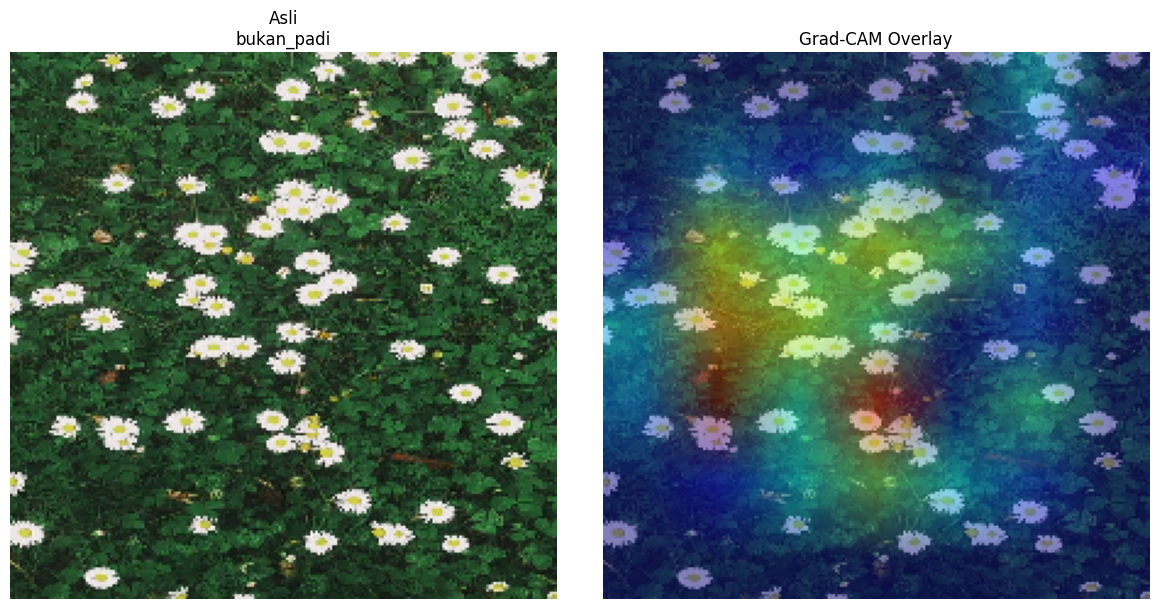

------------------------------
None


In [ ]:
PATH_GAMBAR_UJI = r"C:\Users\abima\OneDrive\Documents\SKRIPSI\SEMHAS\bunga.jpg"

if os.path.exists(PATH_GAMBAR_UJI):
    hasil = prediksi_gambar(
        PATH_GAMBAR_UJI,
        loaded_model,
        alpha_overlay=0.45,
        save_to=None,  
        show=True
    )
    print(hasil)
else:
    print(f"ERROR: File tidak ditemukan di path: {PATH_GAMBAR_UJI}")
    print(r"Mohon periksa kembali path file gambar Anda")
